QUESTION 1: LIBRARIES
Libraries imported successfully!

Data directory: /home/mnit/CryptoLabX_3_Ankit_Nandana/random_generation/data

QUESTION 2: RANDOM DATA VERIFICATION

Linux /dev/urandom
File: data/sample_urandom.bin
Size: 1048576 bytes
Size in MiB: 1.0
STATUS: PASS - At least 1 MiB generated

OpenSSL
File: data/sample_openssl.bin
Size: 1048576 bytes
Size in MiB: 1.0
STATUS: PASS - At least 1 MiB generated

Windows CNG
File: data/sample_windows_cng.bin
STATUS: NOT AVAILABLE YET

QUESTION 3: LOAD RANDOM DATA
Linux /dev/urandom: 1,048,576 bytes (1.00 MiB)
OpenSSL: 1,048,576 bytes (1.00 MiB)

QUESTION 4: BYTE-FREQUENCY DISTRIBUTION

Linux /dev/urandom
------------------------------------------------------------
Total bytes: 1048576
Expected frequency per byte: 4096.0
Chi-square statistic: 250.86962890625
P-value: 0.5613239534892439
Interpretation: No statistically significant evidence of non-uniformity at alpha = 0.05.


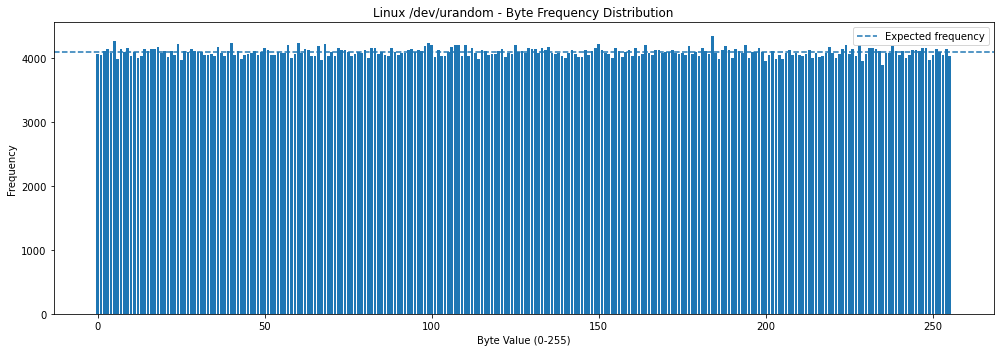


OpenSSL
------------------------------------------------------------
Total bytes: 1048576
Expected frequency per byte: 4096.0
Chi-square statistic: 272.14404296875
P-value: 0.22001584092357213
Interpretation: No statistically significant evidence of non-uniformity at alpha = 0.05.


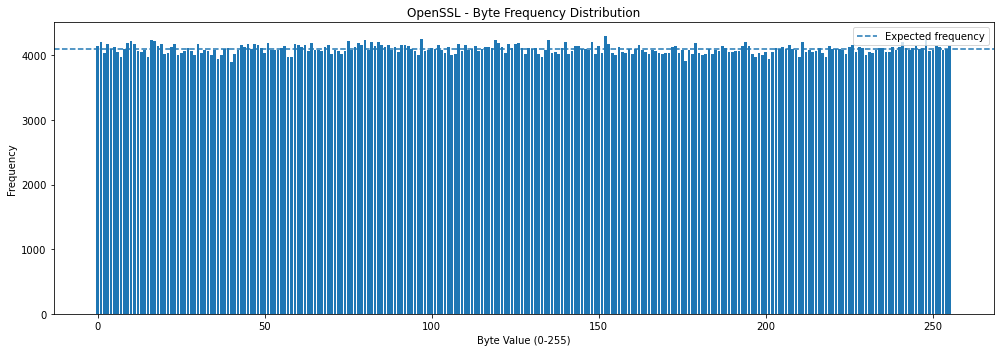


QUESTION 5: BIT DISTRIBUTION

Linux /dev/urandom
------------------------------------------------------------
Total bits: 8,388,608
Zero bits: 4,195,535
One bits: 4,193,073
Percentage of zero bits: 50.014675%
Percentage of one bits: 49.985325%


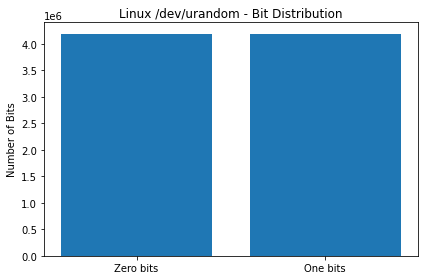


OpenSSL
------------------------------------------------------------
Total bits: 8,388,608
Zero bits: 4,193,235
One bits: 4,195,373
Percentage of zero bits: 49.987257%
Percentage of one bits: 50.012743%


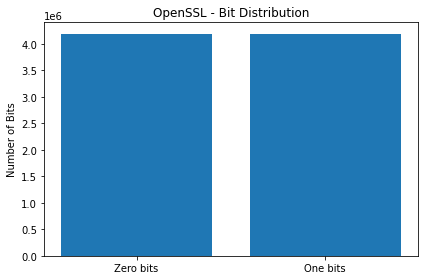


QUESTION 6: SHANNON ENTROPY

Linux /dev/urandom
Shannon entropy: 7.99982768 bits/byte
Maximum possible entropy: 8 bits/byte
Interpretation: Entropy is very close to the theoretical maximum.

OpenSSL
Shannon entropy: 7.99981281 bits/byte
Maximum possible entropy: 8 bits/byte
Interpretation: Entropy is very close to the theoretical maximum.

QUESTION 7: RUNS TEST

Linux /dev/urandom
------------------------------------------------------------
Observed runs: 4191657
Expected runs: 4194304.638709784
Z-score: -1.8282847252681729
P-value: 0.06750683105008233
Interpretation: No statistically significant evidence against randomness in run structure.

OpenSSL
------------------------------------------------------------
Observed runs: 4191896
Expected runs: 4194304.727544546
Z-score: -1.6633083915417204
P-value: 0.09625071981991884
Interpretation: No statistically significant evidence against randomness in run structure.

QUESTION 8: SERIAL CORRELATION

Linux /dev/urandom
Lag 1: -0.0006247591
L

,Generator,Data Size (bytes),Entropy (bits/byte),Chi-square Statistic,Chi-square p-value,Zero Bits,One Bits,Zero %,One %,Observed Runs,Expected Runs,Runs Test p-value,Lag-1 Correlation,Lag-2 Correlation,Lag-3 Correlation,Repeated 16-byte Blocks,Longest Constant Byte Run
0,Linux /dev/urandom,1048576,7.999828,250.869629,0.561324,4195535,4193073,50.014675,49.985325,4191657,4.194305e+06,0.067507,-0.000625,0.001730,0.002915,0,3
1,OpenSSL,1048576,7.999813,272.144043,0.220016,4193235,4195373,49.987257,50.012743,4191896,4.194305e+06,0.096251,-0.000058,-0.001261,0.000688,0,4



QUESTION 13: SAVE RESULTS
Results saved to: /home/mnit/CryptoLabX_3_Ankit_Nandana/random_generation/random_number_analysis.csv
Byte-frequency results saved to: /home/mnit/CryptoLabX_3_Ankit_Nandana/random_generation/byte_frequency_analysis.csv

QUESTION 15: STATISTICAL INTERPRETATION

Linux /dev/urandom
------------------------------------------------------------
Entropy: 7.999828 bits/byte
Chi-square p-value: 0.561324
Runs-test p-value: 0.067507
Lag-1 serial correlation: -0.0006247591
Byte distribution: PASS (no significant deviation detected)
Runs test: PASS (no significant deviation detected)
Serial correlation: LOW

OpenSSL
------------------------------------------------------------
Entropy: 7.999813 bits/byte
Chi-square p-value: 0.220016
Runs-test p-value: 0.096251
Lag-1 serial correlation: -0.0000581886
Byte distribution: PASS (no significant deviation detected)
Runs test: PASS (no significant deviation detected)
Serial correlation: LOW

QUESTION 16: FINAL CONCLUSION

CONCLUSIO

In [19]:
# ============================================================
# CRYPTOGRAPHY LAB
# Evaluation of Operating-System Random-Number Generation
# ============================================================

# ============================================================
# QUESTION 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import os
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chisquare, norm


print("=" * 70)
print("QUESTION 1: LIBRARIES")
print("=" * 70)
print("Libraries imported successfully!")


# ============================================================
# PROJECT PATHS
# ============================================================

BASE_DIR = Path(".")
DATA_DIR = BASE_DIR / "data"

URANDOM_FILE = DATA_DIR / "sample_urandom.bin"
OPENSSL_FILE = DATA_DIR / "sample_openssl.bin"
WINDOWS_FILE = DATA_DIR / "sample_windows_cng.bin"

print("\nData directory:", DATA_DIR.resolve())


# ============================================================
# QUESTION 2: VERIFY GENERATED RANDOM DATA
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 2: RANDOM DATA VERIFICATION")
print("=" * 70)

required_files = {
    "Linux /dev/urandom": URANDOM_FILE,
    "OpenSSL": OPENSSL_FILE,
    "Windows CNG": WINDOWS_FILE
}

for name, path in required_files.items():

    if path.exists():

        size = path.stat().st_size

        print(f"\n{name}")
        print("File:", path)
        print("Size:", size, "bytes")
        print("Size in MiB:", round(size / (1024 * 1024), 2))

        if size >= 1024 * 1024:
            print("STATUS: PASS - At least 1 MiB generated")
        else:
            print("STATUS: FAIL - Less than 1 MiB")

    else:

        print(f"\n{name}")
        print("File:", path)
        print("STATUS: NOT AVAILABLE YET")


# ============================================================
# QUESTION 3: LOAD GENERATED RANDOM DATA
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 3: LOAD RANDOM DATA")
print("=" * 70)


def load_binary_file(path):
    """
    Load binary random data as uint8 NumPy array.
    """
    return np.fromfile(path, dtype=np.uint8)


datasets = {}


if URANDOM_FILE.exists():
    datasets["Linux /dev/urandom"] = load_binary_file(URANDOM_FILE)

if OPENSSL_FILE.exists():
    datasets["OpenSSL"] = load_binary_file(OPENSSL_FILE)

if WINDOWS_FILE.exists():
    datasets["Windows CNG"] = load_binary_file(WINDOWS_FILE)


for name, data in datasets.items():

    print(
        f"{name}: "
        f"{len(data):,} bytes "
        f"({len(data) / (1024 * 1024):.2f} MiB)"
    )


# ============================================================
# QUESTION 4: BYTE-FREQUENCY DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 4: BYTE-FREQUENCY DISTRIBUTION")
print("=" * 70)


def byte_frequency(data):
    """
    Count occurrences of every possible byte value 0-255.
    """
    return np.bincount(data, minlength=256)


def byte_frequency_analysis(data, name):

    frequencies = byte_frequency(data)

    expected_frequency = len(data) / 256

    chi_stat, p_value = chisquare(
        frequencies,
        np.full(256, expected_frequency)
    )

    print(f"\n{name}")
    print("-" * 60)
    print("Total bytes:", len(data))
    print("Expected frequency per byte:", expected_frequency)
    print("Chi-square statistic:", chi_stat)
    print("P-value:", p_value)

    if p_value > 0.05:
        print(
            "Interpretation: No statistically significant "
            "evidence of non-uniformity at alpha = 0.05."
        )
    else:
        print(
            "Interpretation: Significant deviation from "
            "uniformity detected at alpha = 0.05."
        )

    # Plot
    plt.figure(figsize=(14, 5))

    plt.bar(
        range(256),
        frequencies
    )

    plt.axhline(
        expected_frequency,
        linestyle="--",
        label="Expected frequency"
    )

    plt.title(
        name + " - Byte Frequency Distribution"
    )

    plt.xlabel("Byte Value (0-255)")
    plt.ylabel("Frequency")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return {
        "frequencies": frequencies,
        "chi_square": chi_stat,
        "p_value": p_value
    }


byte_results = {}

for name, data in datasets.items():

    byte_results[name] = byte_frequency_analysis(
        data,
        name
    )


# ============================================================
# QUESTION 5: BIT DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 5: BIT DISTRIBUTION")
print("=" * 70)


def bit_distribution_analysis(data, name):

    bits = np.unpackbits(data)

    zeros = int(np.count_nonzero(bits == 0))
    ones = int(np.count_nonzero(bits == 1))

    total_bits = len(bits)

    zero_percentage = zeros / total_bits * 100
    one_percentage = ones / total_bits * 100

    print(f"\n{name}")
    print("-" * 60)

    print("Total bits:", f"{total_bits:,}")
    print("Zero bits:", f"{zeros:,}")
    print("One bits:", f"{ones:,}")

    print(
        "Percentage of zero bits:",
        f"{zero_percentage:.6f}%"
    )

    print(
        "Percentage of one bits:",
        f"{one_percentage:.6f}%"
    )

    # Plot
    plt.figure(figsize=(6, 4))

    plt.bar(
        ["Zero bits", "One bits"],
        [zeros, ones]
    )

    plt.title(
        name + " - Bit Distribution"
    )

    plt.ylabel("Number of Bits")

    plt.tight_layout()
    plt.show()

    return {
        "total_bits": total_bits,
        "zeros": zeros,
        "ones": ones,
        "zero_percentage": zero_percentage,
        "one_percentage": one_percentage
    }


bit_results = {}

for name, data in datasets.items():

    bit_results[name] = bit_distribution_analysis(
        data,
        name
    )


# ============================================================
# QUESTION 6: SHANNON ENTROPY
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 6: SHANNON ENTROPY")
print("=" * 70)


def shannon_entropy(data):

    frequencies = np.bincount(
        data,
        minlength=256
    )

    probabilities = frequencies / len(data)

    probabilities = probabilities[
        probabilities > 0
    ]

    entropy = -np.sum(
        probabilities * np.log2(probabilities)
    )

    return entropy


entropy_results = {}

for name, data in datasets.items():

    entropy = shannon_entropy(data)

    entropy_results[name] = entropy

    print(f"\n{name}")
    print("Shannon entropy:", f"{entropy:.8f} bits/byte")
    print("Maximum possible entropy: 8 bits/byte")

    if entropy >= 7.9:
        print(
            "Interpretation: Entropy is very close "
            "to the theoretical maximum."
        )
    else:
        print(
            "Interpretation: Entropy is below "
            "the theoretical maximum."
        )


# ============================================================
# QUESTION 7: RUNS TEST
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 7: RUNS TEST")
print("=" * 70)


def runs_test(data, name):

    bits = np.unpackbits(data).astype(np.int8)

    n0 = int(np.count_nonzero(bits == 0))
    n1 = int(np.count_nonzero(bits == 1))
    n = len(bits)

    runs = 1 + int(
        np.count_nonzero(
            bits[1:] != bits[:-1]
        )
    )

    expected_runs = (
        1 +
        (2 * n0 * n1) / n
    )

    variance = (
        2 * n0 * n1 *
        (2 * n0 * n1 - n)
        /
        (n ** 2 * (n - 1))
    )

    z_score = (
        (runs - expected_runs)
        /
        np.sqrt(variance)
    )

    p_value = (
        2 * norm.sf(abs(z_score))
    )

    print(f"\n{name}")
    print("-" * 60)

    print("Observed runs:", runs)
    print("Expected runs:", expected_runs)
    print("Z-score:", z_score)
    print("P-value:", p_value)

    if p_value > 0.05:
        print(
            "Interpretation: No statistically significant "
            "evidence against randomness in run structure."
        )
    else:
        print(
            "Interpretation: Significant deviation "
            "detected in run structure."
        )

    return {
        "observed_runs": runs,
        "expected_runs": expected_runs,
        "z_score": z_score,
        "p_value": p_value
    }


runs_results = {}

for name, data in datasets.items():

    runs_results[name] = runs_test(
        data,
        name
    )


# ============================================================
# QUESTION 8: SERIAL CORRELATION
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 8: SERIAL CORRELATION")
print("=" * 70)


def serial_correlation(data, lag=1):

    x = data[:-lag].astype(np.float64)
    y = data[lag:].astype(np.float64)

    return float(
        np.corrcoef(x, y)[0, 1]
    )


correlation_results = {}

for name, data in datasets.items():

    print(f"\n{name}")

    correlations = {}

    for lag in [1, 2, 3, 4, 5]:

        correlation = serial_correlation(
            data,
            lag
        )

        correlations[lag] = correlation

        print(
            f"Lag {lag}: "
            f"{correlation:.10f}"
        )

    correlation_results[name] = correlations


# ============================================================
# QUESTION 9: REPEATED PATTERN ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 9: REPEATED PATTERN ANALYSIS")
print("=" * 70)


def repeated_patterns(data, pattern_length=2, top_n=10):

    patterns = Counter()

    for i in range(
        len(data) - pattern_length + 1
    ):

        pattern = bytes(
            data[i:i + pattern_length]
        )

        patterns[pattern] += 1

    return patterns.most_common(top_n)


pattern_results = {}


for name, data in datasets.items():

    print(f"\n{name}")
    print("-" * 60)

    pattern_results[name] = {}

    for length in [2, 3, 4]:

        result = repeated_patterns(
            data,
            pattern_length=length,
            top_n=10
        )

        pattern_results[name][length] = result

        print(
            f"\nTop repeated {length}-byte patterns:"
        )

        for pattern, count in result:

            print(
                pattern.hex().upper(),
                "->",
                count
            )


# ============================================================
# QUESTION 10: REPEATED 16-BYTE BLOCKS
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 10: REPEATED 16-BYTE BLOCKS")
print("=" * 70)


def repeated_16_byte_blocks(data, name):

    block_size = 16

    usable_length = (
        len(data)
        -
        len(data) % block_size
    )

    blocks = data[
        :usable_length
    ].reshape(
        -1,
        block_size
    )

    block_strings = [
        bytes(block)
        for block in blocks
    ]

    total_blocks = len(
        block_strings
    )

    unique_blocks = len(
        set(block_strings)
    )

    repeated_blocks = (
        total_blocks -
        unique_blocks
    )

    print(f"\n{name}")
    print("-" * 60)

    print("Total 16-byte blocks:", total_blocks)
    print("Unique 16-byte blocks:", unique_blocks)
    print("Repeated 16-byte blocks:", repeated_blocks)

    return {
        "total_blocks": total_blocks,
        "unique_blocks": unique_blocks,
        "repeated_blocks": repeated_blocks
    }


block_results = {}

for name, data in datasets.items():

    block_results[name] = repeated_16_byte_blocks(
        data,
        name
    )


# ============================================================
# QUESTION 11: LONGEST CONSTANT BYTE RUN
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 11: LONGEST CONSTANT BYTE RUN")
print("=" * 70)


def longest_constant_run(data):

    if len(data) == 0:
        return 0

    max_run = 1
    current_run = 1

    for i in range(1, len(data)):

        if data[i] == data[i - 1]:

            current_run += 1

            if current_run > max_run:
                max_run = current_run

        else:

            current_run = 1

    return max_run


constant_run_results = {}

for name, data in datasets.items():

    result = longest_constant_run(data)

    constant_run_results[name] = result

    print(
        name,
        ":",
        result,
        "consecutive identical bytes"
    )


# ============================================================
# QUESTION 12: CREATE FINAL COMPARISON TABLE
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 12: FINAL COMPARISON TABLE")
print("=" * 70)


rows = []


for name, data in datasets.items():

    row = {

        "Generator": name,

        "Data Size (bytes)": len(data),

        "Entropy (bits/byte)": (
            entropy_results[name]
        ),

        "Chi-square Statistic": (
            byte_results[name]["chi_square"]
        ),

        "Chi-square p-value": (
            byte_results[name]["p_value"]
        ),

        "Zero Bits": (
            bit_results[name]["zeros"]
        ),

        "One Bits": (
            bit_results[name]["ones"]
        ),

        "Zero %": (
            bit_results[name]["zero_percentage"]
        ),

        "One %": (
            bit_results[name]["one_percentage"]
        ),

        "Observed Runs": (
            runs_results[name]["observed_runs"]
        ),

        "Expected Runs": (
            runs_results[name]["expected_runs"]
        ),

        "Runs Test p-value": (
            runs_results[name]["p_value"]
        ),

        "Lag-1 Correlation": (
            correlation_results[name][1]
        ),

        "Lag-2 Correlation": (
            correlation_results[name][2]
        ),

        "Lag-3 Correlation": (
            correlation_results[name][3]
        ),

        "Repeated 16-byte Blocks": (
            block_results[name]["repeated_blocks"]
        ),

        "Longest Constant Byte Run": (
            constant_run_results[name]
        )
    }

    rows.append(row)


results = pd.DataFrame(rows)

display(results)


# ============================================================
# QUESTION 13: SAVE RESULTS
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 13: SAVE RESULTS")
print("=" * 70)


OUTPUT_FILE = BASE_DIR / "random_number_analysis.csv"

results.to_csv(
    OUTPUT_FILE,
    index=False
)

print(
    "Results saved to:",
    OUTPUT_FILE.resolve()
)


# ============================================================
# QUESTION 14: CREATE BYTE FREQUENCY CSV
# ============================================================

frequency_table = pd.DataFrame(
    {
        "Byte": range(256)
    }
)

for name, result in byte_results.items():

    safe_name = (
        name
        .replace("/", "_")
        .replace(" ", "_")
    )

    frequency_table[
        safe_name
    ] = result["frequencies"]


frequency_file = (
    BASE_DIR /
    "byte_frequency_analysis.csv"
)

frequency_table.to_csv(
    frequency_file,
    index=False
)

print(
    "Byte-frequency results saved to:",
    frequency_file.resolve()
)


# ============================================================
# QUESTION 15: STATISTICAL INTERPRETATION
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 15: STATISTICAL INTERPRETATION")
print("=" * 70)


for name in datasets:

    chi_p = (
        byte_results[name]["p_value"]
    )

    runs_p = (
        runs_results[name]["p_value"]
    )

    entropy = (
        entropy_results[name]
    )

    correlation = (
        correlation_results[name][1]
    )

    print(f"\n{name}")
    print("-" * 60)

    print(
        f"Entropy: {entropy:.6f} bits/byte"
    )

    print(
        f"Chi-square p-value: {chi_p:.6f}"
    )

    print(
        f"Runs-test p-value: {runs_p:.6f}"
    )

    print(
        f"Lag-1 serial correlation: "
        f"{correlation:.10f}"
    )

    if chi_p > 0.05:
        print(
            "Byte distribution: PASS "
            "(no significant deviation detected)"
        )
    else:
        print(
            "Byte distribution: WARNING "
            "(significant deviation detected)"
        )

    if runs_p > 0.05:
        print(
            "Runs test: PASS "
            "(no significant deviation detected)"
        )
    else:
        print(
            "Runs test: WARNING "
            "(significant deviation detected)"
        )

    if abs(correlation) < 0.01:
        print(
            "Serial correlation: LOW"
        )
    else:
        print(
            "Serial correlation: "
            "non-negligible"
        )


# ============================================================
# QUESTION 16: FINAL CONCLUSION
# ============================================================

print("\n" + "=" * 70)
print("QUESTION 16: FINAL CONCLUSION")
print("=" * 70)

print(
"""
CONCLUSION
----------

The experiment evaluated random data generated using Linux
/dev/urandom, OpenSSL, and, when available, Windows CNG.

The datasets were examined using:

1. Byte-frequency distribution
2. Chi-square uniformity test
3. Bit distribution
4. Shannon entropy
5. Runs test
6. Serial correlation
7. Repeated 2-byte patterns
8. Repeated 3-byte patterns
9. Repeated 4-byte patterns
10. Repeated aligned 16-byte blocks
11. Longest constant-byte runs

A cryptographically strong random source is expected to produce
data that appears statistically random. Therefore, approximately
uniform byte frequencies, balanced zero/one bit counts, high
entropy, low serial correlation, and acceptable statistical-test
results are desirable observations.

However, passing statistical tests DOES NOT prove cryptographic
security.

Statistical tests examine properties of observed output. They
cannot establish that an attacker is unable to predict future
output, recover internal state, determine the generator's seed,
or exploit weaknesses in the implementation.

Cryptographic security depends on additional properties including:

- Quality of entropy sources
- Secure initialization and seeding
- Cryptographically secure pseudorandom generation
- Protection of internal state
- Resistance to prediction
- Resistance to state compromise
- Correct implementation
- Secure operating-system interfaces

Therefore, statistical randomness and cryptographic security
are related but different concepts.

The experiment demonstrates that statistical tests are useful
for detecting certain abnormalities, but they are not sufficient
to certify a random-number generator as cryptographically secure.
"""
)


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("EXPERIMENT COMPLETED")
print("=" * 70)

print("\nDatasets analyzed:")

for name, data in datasets.items():

    print(
        f"  ✓ {name}: "
        f"{len(data):,} bytes"
    )

if not WINDOWS_FILE.exists():

    print(
        "\nNOTE:"
        "\nWindows CNG file is not present yet."
        "\nAdd:"
        "\n  data/sample_windows_cng.bin"
        "\n"
        "\nThen run the notebook again to include Windows CNG."
    )

print(
    "\nGenerated output files:"
)

print(
    "  ✓ random_number_analysis.csv"
)

print(
    "  ✓ byte_frequency_analysis.csv"
)

print(
    "\nAll analysis completed successfully!"
)